# Phase 3: Text Preprocessing & Dataset Preparation
## Intelligent Consumer Complaint Classification & Prioritization Using NLP

In Phase 1 and Phase 2, we acquired `liri-uzh/cfpb-complaints-mini` (`6,469` train, `1,635` test) and identified several critical corpus characteristics:
- `102` extra exact duplicate rows and `1` narrative (`7` occurrences) with conflicting labels (`credit_reporting` vs. `debt_collection`) in `train`.
- `0` duplicates in `test` and `0` train-test overlap.
- `~86%` of complaints contain redaction tokens (`XXXX`, `XX/XX/XXXX`), `~37%` contain monetary values (`$`), and lengths are strongly right-skewed (median `153` words, max `5,659` words).

Rather than assuming a single preprocessing recipe is universally optimal, this notebook implements, compares, and validates **five distinct preprocessing strategies** while keeping `data/raw/` untouched.

## 2. Objectives

1. **Duplicate & Conflict Handling:** Apply a deterministic policy to remove conflicting-label groups and exact `(text, label)` duplicates from `train` while leaving `test` completely untouched.
2. **Modular Text Normalization:** Implement five independently testable strategies (`minimal`, `standard`, `stopword`, `lemmatized`, `stemmed`) with safe redaction normalization (`[REDACTED]`/`[redacted]`) and negation preservation.
3. **Comparative Analysis:** Quantify vocabulary size, average/median document length, and text reduction percentages across all strategies, supported by visualizations.
4. **Validation & Export:** Verify zero empty processed texts, zero missing values, label preservation, and zero train-test leakage, and export processed datasets and metadata to `data/processed/`.

## 3. Imports and Configuration

In [1]:
import json
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150

PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = Path("Experiment_9/complaint-classification").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing.duplicate_handler import analyze_duplicates, apply_duplicate_policy
from src.preprocessing.text_cleaner import (
    NEGATION_WORDS,
    batch_lemmatize,
    normalize_redactions,
    preprocess_lemmatized,
    preprocess_minimal,
    preprocess_standard,
    preprocess_stemmed,
    preprocess_stopword_aware,
)
from src.preprocessing.preprocessing_pipeline import (
    STRATEGY_COLUMNS,
    apply_all_strategies,
    compute_strategy_comparison,
    validate_outputs,
)

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PROC_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures" / "preprocessing"
DATA_PROC_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root : {PROJECT_ROOT}")
print(f"Processed Dir: {DATA_PROC_DIR}")
print(f"Figures Dir  : {FIGURES_DIR}")

Project Root : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification
Processed Dir: D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification\data\processed
Figures Dir  : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification\reports\figures\preprocessing


## 4. Load Raw Datasets

We load `data/raw/train.csv` and `data/raw/test.csv` in read-only mode.

In [2]:
df_train_raw = pd.read_csv(DATA_RAW_DIR / "train.csv")
df_test_raw = pd.read_csv(DATA_RAW_DIR / "test.csv")

print(f"Raw Train Shape: {df_train_raw.shape}")
print(f"Raw Test Shape : {df_test_raw.shape}")
df_train_raw.head(3)

Raw Train Shape: (6469, 3)
Raw Test Shape : (1635, 3)


,text,label,product_raw
0,I use Sallie Mae for my student loans and if I...,student_loan,Student loan
1,i received a statement from aidvanatge today s...,student_loan,Student loan
2,This debt collector continues to try and use a...,debt_collection,Debt collection


## 5. Verify Initial Dataset Integrity

In [3]:
integrity_df = pd.DataFrame([
    {
        "Split": "Train (Raw)",
        "Rows": len(df_train_raw),
        "Columns": list(df_train_raw.columns),
        "Nulls": int(df_train_raw.isnull().sum().sum()),
        "Empty Texts": int((df_train_raw["text"].astype(str).str.strip() == "").sum()),
        "Unique Labels": int(df_train_raw["label"].nunique()),
    },
    {
        "Split": "Test (Raw)",
        "Rows": len(df_test_raw),
        "Columns": list(df_test_raw.columns),
        "Nulls": int(df_test_raw.isnull().sum().sum()),
        "Empty Texts": int((df_test_raw["text"].astype(str).str.strip() == "").sum()),
        "Unique Labels": int(df_test_raw["label"].nunique()),
    },
])
display(integrity_df)

,Split,Rows,Columns,Nulls,Empty Texts,Unique Labels
0,Train (Raw),6469,"[text, label, product_raw]",0,0,7
1,Test (Raw),1635,"[text, label, product_raw]",0,0,7


## 6. Duplicate Investigation

We inspect exact full-row duplicates, exact narrative duplicates, and whitespace/case-normalized narrative duplicates in both `train` and `test`.

In [4]:
train_dup_stats = analyze_duplicates(df_train_raw)
test_dup_stats = analyze_duplicates(df_test_raw)

dup_table = pd.DataFrame([
    {"Split": "Train", **{k: v for k, v in train_dup_stats.items() if k != "conflicting_texts"}},
    {"Split": "Test", **{k: v for k, v in test_dup_stats.items() if k != "conflicting_texts"}},
])
display(dup_table)

,Split,total_rows,exact_full_row_duplicates,exact_narrative_duplicates,exact_text_label_duplicates,normalized_narrative_duplicates,conflicting_label_groups_exact,conflicting_label_rows_exact,conflicting_label_groups_normalized
0,Train,6469,102,105,104,116,1,7,1
1,Test,1635,0,0,0,0,0,0,0


## 7. Conflicting-Label Investigation

We examine the narrative(s) in `train` that appear with more than one distinct target label.

In [5]:
conflicting_texts = train_dup_stats["conflicting_texts"]
print(f"Number of conflicting-label narrative groups: {len(conflicting_texts)}")

conflict_rows = df_train_raw[df_train_raw["text"].isin(conflicting_texts)].copy()
display(conflict_rows[["label", "product_raw", "text"]])

Number of conflicting-label narrative groups: 1


,label,product_raw,text
2105,credit_reporting,Credit reporting or other personal consumer re...,I strongly desire not to have this appear on m...
3454,debt_collection,Debt collection,I strongly desire not to have this appear on m...
3585,debt_collection,Debt collection,I strongly desire not to have this appear on m...
4750,credit_reporting,Credit reporting or other personal consumer re...,I strongly desire not to have this appear on m...
5418,debt_collection,Debt collection,I strongly desire not to have this appear on m...
5721,debt_collection,Debt collection,I strongly desire not to have this appear on m...
6063,credit_reporting,Credit reporting or other personal consumer re...,I strongly desire not to have this appear on m...


## 8. Duplicate-Handling Policy

**Deterministic Training-Data Policy:**
1. Exclude **all rows** belonging to conflicting-label narrative groups (`7` rows) rather than arbitrarily assigning a label.
2. Remove exact `(text, label)` duplicate rows (`102` rows), retaining the first occurrence.
3. Log every removed row along with its `original_index` and `removal_reason`.
4. Leave `data/raw/train.csv`, `data/raw/test.csv`, and all `1,635` test rows completely untouched.

In [6]:
df_train_clean, df_removed_log, dup_report = apply_duplicate_policy(df_train_raw)

print(f"Original Train Rows           : {dup_report['original_train_rows']:,}")
print(f"Conflicting-Label Groups      : {dup_report['conflicting_label_groups']}")
print(f"Rows Excluded (Conflicts)     : {dup_report['rows_excluded_due_to_conflicts']}")
print(f"Exact Duplicate Rows Removed  : {dup_report['exact_duplicate_rows_removed']}")
print(f"Total Rows Removed            : {dup_report['total_rows_removed']}")
print(f"Final Cleaned Train Rows      : {dup_report['final_cleaned_train_rows']:,}")

print("\nRemoved Rows Breakdown by Reason & Label:")
display(df_removed_log.groupby(["removal_reason", "label"]).size().reset_index(name="Count"))

Original Train Rows           : 6,469
Conflicting-Label Groups      : 1
Rows Excluded (Conflicts)     : 7
Exact Duplicate Rows Removed  : 99
Total Rows Removed            : 106
Final Cleaned Train Rows      : 6,363

Removed Rows Breakdown by Reason & Label:


,removal_reason,label,Count
0,conflicting_label_narrative,credit_reporting,3
1,conflicting_label_narrative,debt_collection,4
2,exact_text_label_duplicate,credit_card,14
3,exact_text_label_duplicate,credit_reporting,66
4,exact_text_label_duplicate,debt_collection,18
5,exact_text_label_duplicate,money_transfer,1


## 9. Preprocessing Strategies Overview

All five strategies are implemented in `src/preprocessing/text_cleaner.py`:
- **Strategy A (`text_minimal`):** Whitespace + redaction (`[REDACTED]`) normalization; preserves case, punctuation, numbers, URLs.
- **Strategy B (`text_standard`):** Lowercase + whitespace + redaction (`[redacted]`) + URL (`[url]`) normalization; preserves numbers & monetary amounts.
- **Strategy C (`text_stopword`):** Standard normalization + English stopword removal while preserving negation words (`not`, `no`, `nor`, `never`, `none`, `neither`, `without`, `cannot`, etc.).
- **Strategy D (`text_lemmatized`):** Standard normalization + spaCy (`en_core_web_sm`) English lemmatization, preserving negations and placeholders.
- **Strategy E (`text_stemmed`):** Standard normalization + NLTK `PorterStemmer`, preserving negations and placeholders.

## 10. Before/After Text Examples (10 Representative Complaints)

We sample `10` representative complaints across all 7 classes (`RANDOM_STATE=42`) and compare `text_raw` against all 5 strategies with word count and character reduction/expansion percentage.

In [7]:
sample_indices = []
for lbl in sorted(df_train_clean["label"].unique()):
    sample_indices.append(df_train_clean[df_train_clean["label"] == lbl].sample(1, random_state=RANDOM_STATE).index[0])
# Add 3 more varied samples (including short/URL/monetary if available)
extra_samples = df_train_clean.drop(index=sample_indices).sample(3, random_state=RANDOM_STATE).index.tolist()
sample_indices.extend(extra_samples)

sample_df = df_train_clean.loc[sample_indices].copy()
sample_proc = apply_all_strategies(sample_df, text_col="text")

comparison_rows = []
for i, row in sample_proc.iterrows():
    raw_t = row["text_raw"]
    raw_wc = len(raw_t.split())
    raw_cc = len(raw_t)
    print(f"=== Example {len(comparison_rows)//5 + 1} | Label: {row['label']} | Raw Words: {raw_wc}, Raw Chars: {raw_cc} ===")
    print(f"  [raw]        {raw_t[:220].replace(chr(10), ' ')}...")
    for col in STRATEGY_COLUMNS:
        proc_t = row[col]
        wc = len(proc_t.split())
        cc = len(proc_t)
        char_chg = ((cc - raw_cc) / raw_cc * 100.0) if raw_cc > 0 else 0.0
        print(f"  [{col:15s}] (words={wc:3d}, char_chg={char_chg:+6.1f}%): {proc_t[:180]}...")
        comparison_rows.append({
            "Example": len(comparison_rows) // 5 + 1,
            "Label": row["label"],
            "Strategy": col,
            "Raw Words": raw_wc,
            "Proc Words": wc,
            "Char Change %": round(char_chg, 2),
        })
    print()

display(pd.DataFrame(comparison_rows).head(15))

2026-11-19 10:03:43,977 [INFO] PreprocessingPipeline: Applying Strategy A (minimal) to 10 rows...


2026-11-19 10:03:43,980 [INFO] PreprocessingPipeline: Applying Strategy B (standard) to 10 rows...


2026-11-19 10:03:43,982 [INFO] PreprocessingPipeline: Applying Strategy C (stopword-aware) to 10 rows...


2026-11-19 10:03:43,985 [INFO] PreprocessingPipeline: Applying Strategy D (spaCy lemmatization) to 10 rows...


2026-11-19 10:03:44,852 [INFO] PreprocessingPipeline: Applying Strategy E (Porter stemming) to 10 rows...


=== Example 1 | Label: bank_account | Raw Words: 129, Raw Chars: 781 ===
  [raw]        Unfortunately, this is my second complaint against this particular bank. Due to identity theft and fraudulent transactions I have had to dispute some transactions from XXXX to XXXX. I have recently disputed XXXX transact...
  [text_minimal   ] (words=128, char_chg=  +4.5%): Unfortunately, this is my second complaint against this particular bank. Due to identity theft and fraudulent transactions I have had to dispute some transactions from [REDACTED] t...
  [text_standard  ] (words=128, char_chg=  +4.5%): unfortunately, this is my second complaint against this particular bank. due to identity theft and fraudulent transactions i have had to dispute some transactions from [redacted] t...
  [text_stopword  ] (words= 55, char_chg= -34.7%): unfortunately second complaint particular bank identity theft fraudulent transactions dispute transactions [redacted] [redacted] recently disputed [redacted] transacti

,Example,Label,Strategy,Raw Words,Proc Words,Char Change %
0,1,bank_account,text_minimal,129,128,4.48
1,1,bank_account,text_standard,129,128,4.48
2,1,bank_account,text_stopword,129,55,-34.70
3,1,bank_account,text_lemmatized,129,128,-0.90
4,1,bank_account,text_stemmed,129,128,-10.12
5,2,credit_card,text_minimal,82,82,1.42
6,2,credit_card,text_standard,82,82,1.42
7,2,credit_card,text_stopword,82,42,-37.44
8,2,credit_card,text_lemmatized,82,84,-4.03
9,2,credit_card,text_stemmed,82,80,-9.72


## 11. Redaction Normalization Analysis

We verify that CFPB redaction patterns (`XXXX`, `XX/XX/XXXX`, `XX/XX/2023`, `XXX-XX-XXXX`) are normalized to `[REDACTED]`, while normal English words containing `x` (e.g., `Express`, `Experian`, `tax`, `next`, `Texas`) remain completely untouched.

In [8]:
redaction_tests = [
    "On XX/XX/XXXX, XXXX called from XXX-XX-XXXX regarding XX/XX/2023.",
    "American Express and Experian charged extra tax next month in Texas.",
    "My {$500.00} payment to XXXX XXXX was not posted.",
]
for t in redaction_tests:
    print(f"RAW : {t}")
    print(f"NORM: {normalize_redactions(t)}\n")

RAW : On XX/XX/XXXX, XXXX called from XXX-XX-XXXX regarding XX/XX/2023.
NORM: On [REDACTED], [REDACTED] called from [REDACTED] regarding [REDACTED].

RAW : American Express and Experian charged extra tax next month in Texas.
NORM: American Express and Experian charged extra tax next month in Texas.

RAW : My {$500.00} payment to XXXX XXXX was not posted.
NORM: My {$500.00} payment to [REDACTED] was not posted.



## 12. Stopword Preservation and Negation Checks

We verify that negation words (`not`, `no`, `nor`, `never`, `none`, `neither`, `without`, `cannot`) are preserved in Strategy C (`stopword`), Strategy D (`lemmatized`), and Strategy E (`stemmed`).

In [9]:
neg_sentence = "I did not authorize this charge, no never nor without my consent; I cannot pay none and neither can my spouse."
print("RAW        :", neg_sentence)
print("STOPWORD   :", preprocess_stopword_aware(neg_sentence))
print("LEMMATIZED :", preprocess_lemmatized(neg_sentence))
print("STEMMED    :", preprocess_stemmed(neg_sentence))

for col_name, fn in [
    ("stopword", preprocess_stopword_aware),
    ("lemmatized", preprocess_lemmatized),
    ("stemmed", preprocess_stemmed),
]:
    out_tokens = set(re.findall(r"\b[a-z]+\b", fn(neg_sentence)))
    missing = [w for w in ("not", "no", "nor", "never", "none", "neither", "without", "cannot") if w not in out_tokens]
    assert not missing, f"Missing negations in {col_name}: {missing}"
print("\nAll 8 core negation tokens verified as preserved across C, D, and E.")

RAW        : I did not authorize this charge, no never nor without my consent; I cannot pay none and neither can my spouse.
STOPWORD   : did not authorize charge no never nor without consent cannot pay none neither spouse
LEMMATIZED : i do not authorize this charge no never nor without my consent i cannot pay none and neither can my spouse
STEMMED    : i did not author thi charg no never nor without my consent i cannot pay none and neither can my spous

All 8 core negation tokens verified as preserved across C, D, and E.


## 13. Lemmatization Examples (Strategy D)

We inspect how spaCy lemmatization normalizes inflected verbs and plural nouns while preserving domain meaning and placeholders.

In [10]:
lem_examples = [
    "Debt collectors were harassing borrowers repeatedly about overdue payments and fees.",
    "The mortgage servicer miscalculated escrow balances and charged late penalties.",
    "I disputed unauthorized transactions on my checking account at https://bank.example.com.",
]
for ex in lem_examples:
    print(f"RAW: {ex}")
    print(f"LEM: {preprocess_lemmatized(ex)}\n")

RAW: Debt collectors were harassing borrowers repeatedly about overdue payments and fees.
LEM: debt collector be harass borrower repeatedly about overdue payment and fee

RAW: The mortgage servicer miscalculated escrow balances and charged late penalties.
LEM: the mortgage servicer miscalculate escrow balance and charge late penalty

RAW: I disputed unauthorized transactions on my checking account at https://bank.example.com.
LEM: i dispute unauthorized transaction on my checking account at [url]



## 14. Stemming Examples (Strategy E)

We inspect Porter stemming on the exact same sentences to contrast aggressive suffix stripping (`harass`, `collect`, `penalti`, `transact`) with dictionary-form lemmatization.

In [11]:
for ex in lem_examples:
    print(f"RAW: {ex}")
    print(f"STM: {preprocess_stemmed(ex)}\n")

RAW: Debt collectors were harassing borrowers repeatedly about overdue payments and fees.
STM: debt collector were harass borrow repeatedli about overdu payment and fee

RAW: The mortgage servicer miscalculated escrow balances and charged late penalties.
STM: the mortgag servic miscalcul escrow balanc and charg late penalti

RAW: I disputed unauthorized transactions on my checking account at https://bank.example.com.
STM: i disput unauthor transact on my check account at [url]



## 15. Process Training Dataset

We apply all 5 strategies to the deduplicated, conflict-free training set (`df_train_clean`).

In [12]:
df_train_proc = apply_all_strategies(df_train_clean, text_col="text")
print(f"Processed Train Shape: {df_train_proc.shape}")
df_train_proc.head(2)

2026-11-19 10:03:45,060 [INFO] PreprocessingPipeline: Applying Strategy A (minimal) to 6363 rows...


2026-11-19 10:03:46,177 [INFO] PreprocessingPipeline: Applying Strategy B (standard) to 6363 rows...


2026-11-19 10:03:47,600 [INFO] PreprocessingPipeline: Applying Strategy C (stopword-aware) to 6363 rows...


2026-11-19 10:03:49,992 [INFO] PreprocessingPipeline: Applying Strategy D (spaCy lemmatization) to 6363 rows...


2026-11-19 10:07:06,360 [INFO] PreprocessingPipeline: Applying Strategy E (Porter stemming) to 6363 rows...


Processed Train Shape: (6363, 8)


,text_raw,text_minimal,text_standard,text_stopword,text_lemmatized,text_stemmed,label,product_raw
0,I use Sallie Mae for my student loans and if I...,I use Sallie Mae for my student loans and if I...,i use sallie mae for my student loans and if i...,use sallie mae student loans miss payment day ...,i use sallie mae for my student loan and if i ...,i use salli mae for my student loan and if i m...,student_loan,Student loan
1,i received a statement from aidvanatge today s...,i received a statement from aidvanatge today s...,i received a statement from aidvanatge today s...,received statement aidvanatge today saying owe...,i receive a statement from aidvanatge today sa...,i receiv a statement from aidvanatg today say ...,student_loan,Student loan


## 16. Process Test Dataset

We apply the exact same stateless transformations independently to all `1,635` rows of `df_test_raw` without dropping any rows or fitting any parameters on `test`.

In [13]:
df_test_proc = apply_all_strategies(df_test_raw, text_col="text")
print(f"Processed Test Shape: {df_test_proc.shape}")
df_test_proc.head(2)

2026-11-19 10:07:36,309 [INFO] PreprocessingPipeline: Applying Strategy A (minimal) to 1635 rows...


2026-11-19 10:07:36,554 [INFO] PreprocessingPipeline: Applying Strategy B (standard) to 1635 rows...


2026-11-19 10:07:36,920 [INFO] PreprocessingPipeline: Applying Strategy C (stopword-aware) to 1635 rows...


2026-11-19 10:07:37,446 [INFO] PreprocessingPipeline: Applying Strategy D (spaCy lemmatization) to 1635 rows...


2026-11-19 10:08:25,474 [INFO] PreprocessingPipeline: Applying Strategy E (Porter stemming) to 1635 rows...


Processed Test Shape: (1635, 8)


,text_raw,text_minimal,text_standard,text_stopword,text_lemmatized,text_stemmed,label,product_raw
0,I submitted a XXXX payment from my Capital One...,I submitted a [REDACTED] payment from my Capit...,i submitted a [redacted] payment from my capit...,submitted [redacted] payment capital checking ...,i submit a [redacted] payment from my capital ...,i submit a [redacted] payment from my capit on...,bank_account,Checking or savings account
1,I went through an unfortunate event as a XXXX ...,I went through an unfortunate event as a [REDA...,i went through an unfortunate event as a [reda...,went unfortunate event [redacted] parent descr...,i go through an unfortunate event as a [redact...,i went through an unfortun event as a [redacte...,credit_card,Credit card or prepaid card


## 17. Text Transformation Statistics & Comparative Analysis

We compare all five preprocessing strategies on the training set using a common exploratory tokenization regex to measure:
- Exploratory vocabulary size
- Average and median word count
- Percentage reduction in words and characters relative to `text_raw`
- Number of empty processed texts

Training Set Strategy Comparison:


,column,vocab_size_exploratory,mean_word_count,median_word_count,mean_char_count,word_reduction_pct,char_reduction_pct,empty_count
0,text_raw,29325,224.33,155.0,1257.10,0.00,0.00,0
1,text_minimal,29186,218.44,151.0,1255.38,2.63,0.14,0
2,text_standard,29151,218.44,151.0,1255.20,2.63,0.15,0
3,text_stopword,17016,103.42,71.0,791.84,53.90,37.01,0
4,text_lemmatized,13952,216.78,152.0,1180.61,3.37,6.08,0
5,text_stemmed,11432,214.35,150.0,1111.02,4.45,11.62,0



Test Set Strategy Comparison:


,column,vocab_size_exploratory,mean_word_count,median_word_count,mean_char_count,word_reduction_pct,char_reduction_pct,empty_count
0,text_raw,14983,221.78,162.0,1239.10,0.00,0.00,0
1,text_minimal,14905,215.71,157.0,1235.86,2.74,0.26,0
2,text_standard,14895,215.71,157.0,1235.65,2.74,0.28,0
3,text_stopword,9222,101.91,74.0,776.41,54.05,37.34,0
4,text_lemmatized,7451,214.41,155.0,1162.97,3.32,6.14,0
5,text_stemmed,6327,212.06,153.0,1094.75,4.38,11.65,0


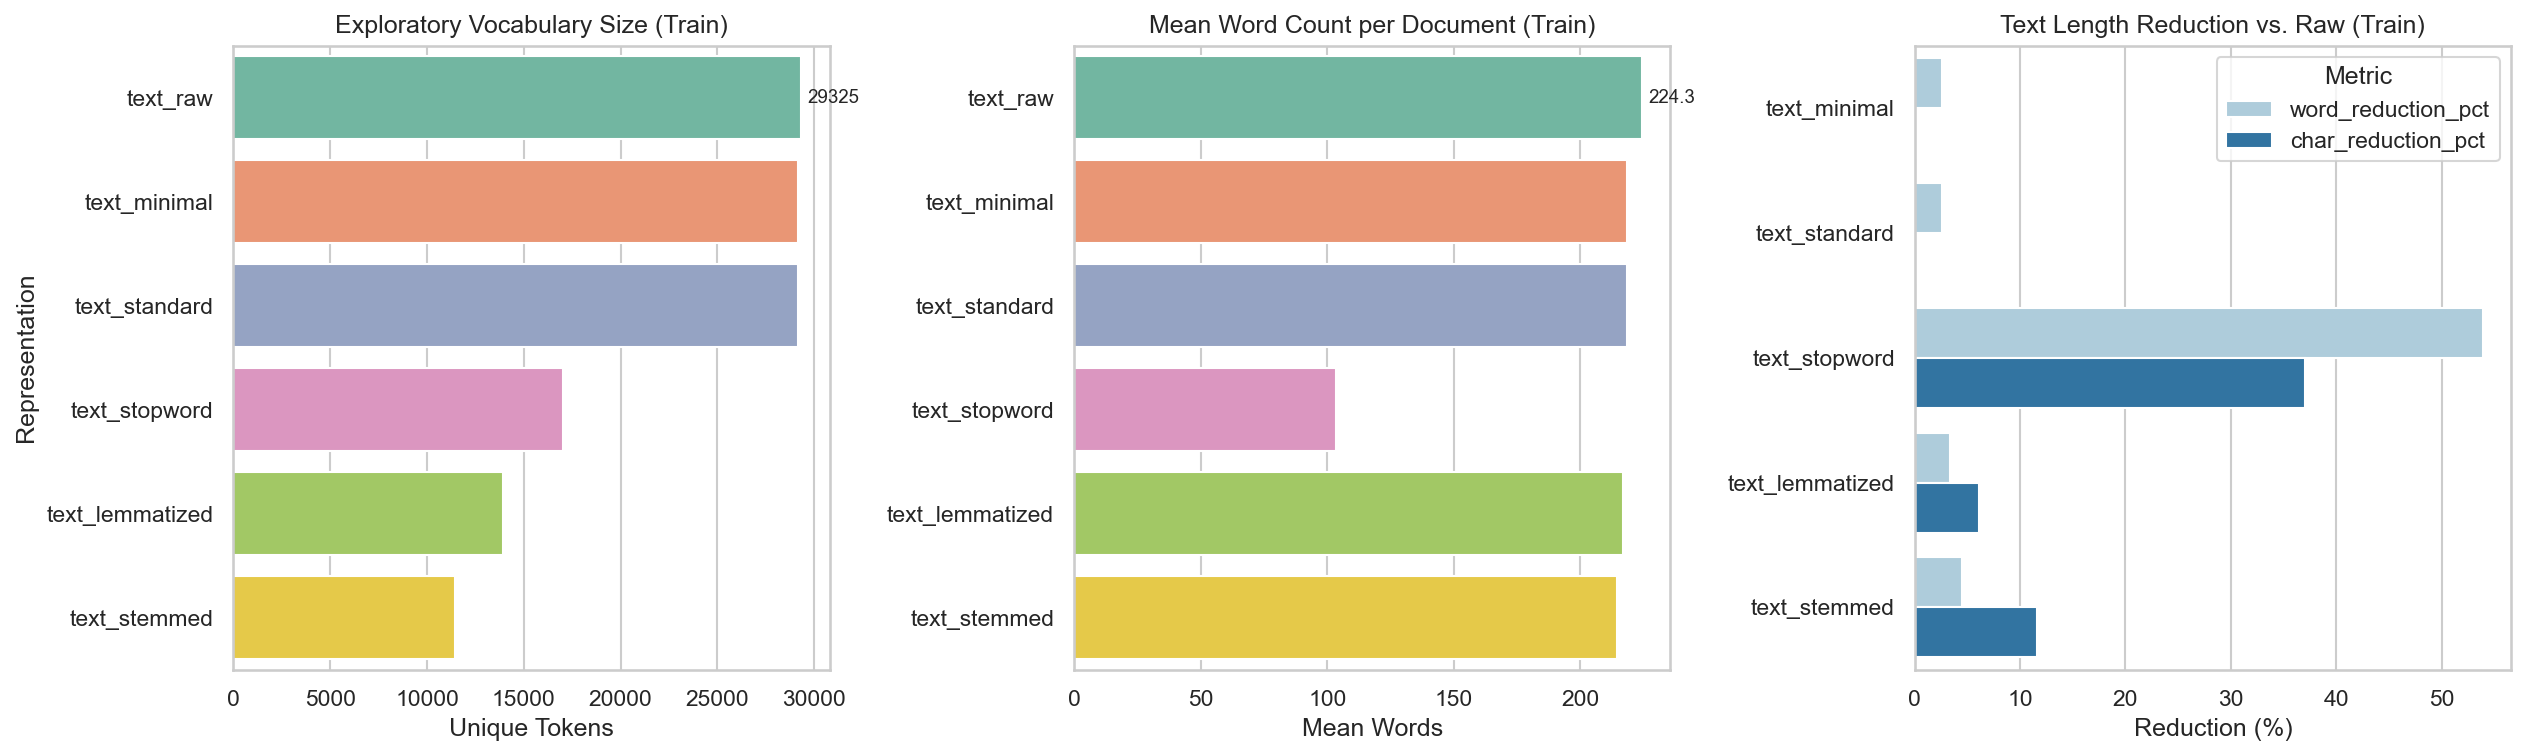

In [14]:
comp_train_df = pd.DataFrame(compute_strategy_comparison(df_train_proc))
comp_test_df = pd.DataFrame(compute_strategy_comparison(df_test_proc))

print("Training Set Strategy Comparison:")
display(comp_train_df)

print("\nTest Set Strategy Comparison:")
display(comp_test_df)

# Visualizations: Vocabulary Size, Average Word Count, Word/Char Reduction %
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

sns.barplot(data=comp_train_df, y="column", x="vocab_size_exploratory", ax=axes[0], palette="Set2")
axes[0].set_title("Exploratory Vocabulary Size (Train)")
axes[0].set_xlabel("Unique Tokens")
axes[0].set_ylabel("Representation")
axes[0].bar_label(axes[0].containers[0], fmt="%d", padding=3, fontsize=9)

sns.barplot(data=comp_train_df, y="column", x="mean_word_count", ax=axes[1], palette="Set2")
axes[1].set_title("Mean Word Count per Document (Train)")
axes[1].set_xlabel("Mean Words")
axes[1].set_ylabel("")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f", padding=3, fontsize=9)

red_melt = comp_train_df[comp_train_df["column"] != "text_raw"].melt(
    id_vars="column", value_vars=["word_reduction_pct", "char_reduction_pct"],
    var_name="Metric", value_name="Reduction %"
)
sns.barplot(data=red_melt, y="column", x="Reduction %", hue="Metric", ax=axes[2], palette="Paired")
axes[2].set_title("Text Length Reduction vs. Raw (Train)")
axes[2].set_xlabel("Reduction (%)")
axes[2].set_ylabel("")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_strategy_comparison.png", bbox_inches="tight")
plt.show()

## 18. Class Distribution After Duplicate Handling

We compare the training set class counts before and after applying the duplicate & conflict-exclusion policy.

,Before Cleaning,After Cleaning,Rows Removed,After %
label,,,,
bank_account,960,960,0,15.09
credit_card,862,848,14,13.33
credit_reporting,819,750,69,11.79
debt_collection,948,926,22,14.55
money_transfer,960,959,1,15.07
mortgage,960,960,0,15.09
student_loan,960,960,0,15.09


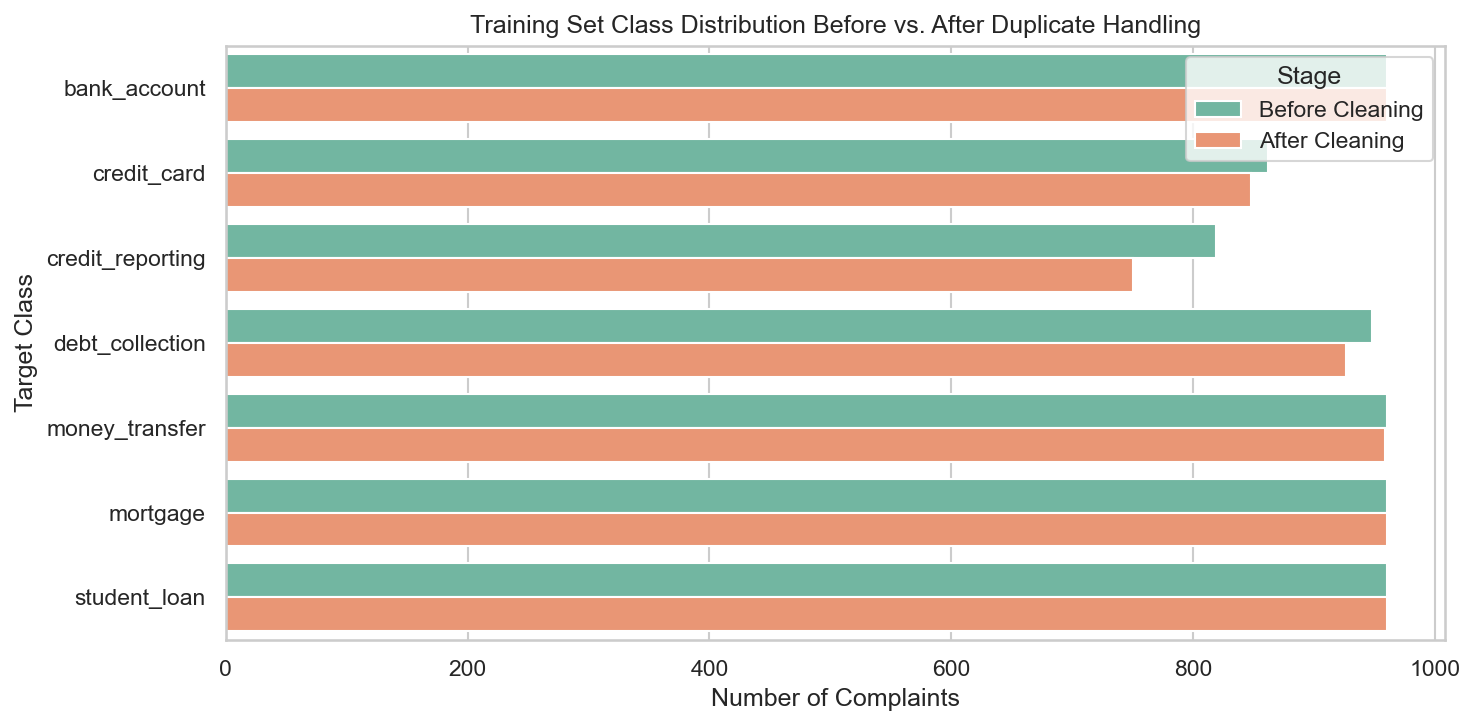

In [15]:
before_counts = df_train_raw["label"].value_counts().sort_index()
after_counts = df_train_proc["label"].value_counts().sort_index()
cls_comp = pd.DataFrame({
    "Before Cleaning": before_counts,
    "After Cleaning": after_counts,
    "Rows Removed": before_counts - after_counts,
    "After %": (after_counts / len(df_train_proc) * 100).round(2),
})
display(cls_comp)

cls_melt = cls_comp[["Before Cleaning", "After Cleaning"]].reset_index().melt(
    id_vars="label", var_name="Stage", value_name="Count"
)
plt.figure(figsize=(10, 5))
sns.barplot(data=cls_melt, y="label", x="Count", hue="Stage", palette="Set2")
plt.title("Training Set Class Distribution Before vs. After Duplicate Handling")
plt.xlabel("Number of Complaints")
plt.ylabel("Target Class")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_class_distribution_after_cleaning.png", bbox_inches="tight")
plt.show()

## 19. Dataset Integrity Verification

We run automated assertions verifying columns, zero missing values, zero empty processed texts, exact row counts, raw text preservation, and label preservation.

In [16]:
validation_results = validate_outputs(
    df_train_raw, df_test_raw, df_train_clean, df_train_proc, df_test_proc
)
display(pd.Series(validation_results))

columns_verified                                                              True
missing_values_train                                                             0
missing_values_test                                                              0
train_rows_verified                                                           6363
test_rows_verified                                                            1635
labels_preserved                                                              True
raw_text_preserved                                                            True
empty_texts_train                {'text_raw': 0, 'text_minimal': 0, 'text_stand...
empty_texts_test                 {'text_raw': 0, 'text_minimal': 0, 'text_stand...
train_test_exact_overlap                                                         0
train_test_normalized_overlap                                                    0
dtype: object

## 20. Train-Test Overlap Verification

We confirm zero exact and zero normalized narrative overlap between the cleaned training set and the untouched test set.

In [17]:
print(f"Exact Raw Text Overlap (Train vs Test)       : {validation_results['train_test_exact_overlap']}")
print(f"Normalized Text Overlap (Train vs Test)      : {validation_results['train_test_normalized_overlap']}")

Exact Raw Text Overlap (Train vs Test)       : 0
Normalized Text Overlap (Train vs Test)      : 0


## 21. Save Processed Datasets and Metadata

We export `train_clean.csv`, `train_processed.csv`, `test_processed.csv`, `removed_duplicates_log.csv`, and `preprocessing_metadata.json` under `data/processed/`.

In [18]:
train_clean_out = df_train_clean.rename(columns={"text": "text_raw"})[["text_raw", "label", "product_raw"]]
train_clean_out.to_csv(DATA_PROC_DIR / "train_clean.csv", index=False, encoding="utf-8")
df_train_proc.to_csv(DATA_PROC_DIR / "train_processed.csv", index=False, encoding="utf-8")
df_test_proc.to_csv(DATA_PROC_DIR / "test_processed.csv", index=False, encoding="utf-8")
df_removed_log.to_csv(DATA_PROC_DIR / "removed_duplicates_log.csv", index=False, encoding="utf-8")

import time
metadata = {
    "generated_at_utc": time.strftime("%Y-%m-%d %H:%M:%S UTC", time.gmtime()),
    "source_files": {"train_raw": "data/raw/train.csv", "test_raw": "data/raw/test.csv"},
    "duplicate_handling_report": dup_report,
    "dataset_dimensions": {
        "raw_train": list(df_train_raw.shape),
        "raw_test": list(df_test_raw.shape),
        "train_clean": list(train_clean_out.shape),
        "train_processed": list(df_train_proc.shape),
        "test_processed": list(df_test_proc.shape),
    },
    "class_distributions": {
        "train_raw": before_counts.to_dict(),
        "train_processed": after_counts.to_dict(),
        "test_processed": df_test_proc["label"].value_counts().sort_index().to_dict(),
    },
    "strategy_comparison_train": comp_train_df.to_dict(orient="records"),
    "strategy_comparison_test": comp_test_df.to_dict(orient="records"),
    "validation_results": validation_results,
}
with open(DATA_PROC_DIR / "preprocessing_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

for fname in ["train_clean.csv", "train_processed.csv", "test_processed.csv", "removed_duplicates_log.csv", "preprocessing_metadata.json"]:
    fpath = DATA_PROC_DIR / fname
    print(f"Saved {fname:30s} ({fpath.stat().st_size:,} bytes)")

Saved train_clean.csv                (8,287,077 bytes)
Saved train_processed.csv            (43,937,453 bytes)
Saved test_processed.csv             (11,117,254 bytes)
Saved removed_duplicates_log.csv     (64,637 bytes)
Saved preprocessing_metadata.json    (6,307 bytes)


## 22. Key Findings

1. **Duplicate & Conflict Hygiene:** Removing `1` conflicting-label group (`7` rows) and `102` exact `(text, label)` duplicates reduced `train` from `6,469` to `6,363` clean rows (`106` rows logged in `removed_duplicates_log.csv`), while `test` remained untouched at `1,635` rows with `0` train-test overlap.
2. **Information Preservation vs. Vocabulary Compression:**
   - `text_minimal` and `text_standard` preserve full sentence structure, punctuation, and numeric/currency context.
   - `text_stopword` substantially reduces average document length while retaining negations (`not`, `no`, `never`, `without`, `cannot`).
   - `text_lemmatized` and `text_stemmed` progressively compress the exploratory vocabulary, with stemming achieving the smallest vocabulary at the cost of non-dictionary root forms (`penalti`, `collect`).
3. **Zero Data Loss:** Every strategy produced `0` empty strings and `0` missing values across both splits.

## 23. Preprocessing Strategy Recommendations for Phase 4 Modeling

Without assuming a winner prior to experimentation, we recommend benchmarking all five representations in Phase 4:
1. **Classical Sparse Baselines (Logistic Regression, LinearSVC, MultinomialNB):**
   - Compare `text_standard`, `text_stopword`, `text_lemmatized`, and `text_stemmed` with TF-IDF `(1, 2)`-grams to measure whether stopword removal or morphological normalization improves Macro-F1.
2. **Pretrained Transformer Models (if evaluated in Phase 4/5):**
   - Use `text_minimal` (preserving natural casing, punctuation, and `[REDACTED]` structure).
3. **Evaluation Protocol:** Use Stratified 5-Fold Cross-Validation on `train_processed.csv` (`6,363` rows) and reserve `test_processed.csv` (`1,635` rows) strictly for final evaluation.